# 线性回归课堂笔记：从相关分析到正则化

本 Notebook 按《机器学习课堂笔记(4)》《(5)》《(6)》《(8)》整理，覆盖：

- conda 环境与 Jupyter 内核
- 广告投放案例：相关系数、散点图
- 假设函数、sklearn 要求的数据形状
- 单特征 / 多特征线性回归
- 预测、MAE / RMSE / R² 与残差图
- 损失函数、最小二乘法与正规方程
- 梯度下降：学习率、特征标准化、与正规方程的对比
- 回归评估指标 MAE / RMSE / R² 的读法
- 标准化后的系数比较：谁的影响更大
- 过拟合与正则化：Ridge / Lasso / alpha

数据：`data/广告数据.csv`（200 周，微信/微博/抖音投入与销售额）。

依赖：

```bash
pip install numpy pandas scikit-learn matplotlib
```

> 本 Notebook 位于 `notebooks/` 目录，数据路径统一写作 `../data/广告数据.csv`；如果在项目根目录运行，请改成 `data/广告数据.csv`。

## 0. conda 环境与 Jupyter 内核

每个 conda 环境是一套独立隔离的 Python + 包版本，环境之间互不干扰。`base` 是 Anaconda 默认环境，项目依赖建议单独建环境。

### 0.1 常用命令

```bash
# 查看所有环境（同时能看到安装位置）
conda env list

# 创建环境
conda create -n 环境名称

# 创建时直接装好 Python 和 Jupyter 内核
conda create -n 环境名称 python=3.12 ipykernel -y

# 激活 / 退出
conda activate 环境名称
conda deactivate

# 删除环境（先退出要删除的环境）
conda env remove -n 环境名称
```

### 0.2 把环境注册到 Jupyter

Jupyter 默认不知道你新建的 conda 环境，需要注册内核：

```bash
conda activate 环境名称
python -m ipykernel install --user --name 项目名 --display-name "Jupyter 中显示的名称"
```

- `--name`：内核的唯一标识，建议用英文；
- `--display-name`：Jupyter 下拉框中显示的名字，可以用中文；
- 注册后刷新或重启 Jupyter，才能看到新内核。

查看和删除内核：

```bash
jupyter kernelspec list
jupyter kernelspec remove 内核名称
```

注意：`jupyter kernelspec remove` 用的是**内核名称**（`--name` 的值），不是 conda 环境名称。

> Python 版本建议 3.11 / 3.12。笔记里写的 Python 3.14 很新，部分科学计算包可能尚未完全适配。

## 1. 从分类到回归

- **分类**：输出类别，例如“这朵花是哪个品种”。
- **回归**：输出连续数值，例如“这周销售额是多少万元”。

线性回归就是找一条最贴合数据的直线（或多个特征时的超平面），描述特征与标签之间的近似线性关系，再用它做预测。

### 广告案例的 T、P、E

一家网店记录了 200 周的数据：每周在微信、微博、抖音三个渠道各投多少钱（千元），这一周卖了多少钱（万元）。

- **T（任务）**：根据三个渠道的投入预测销售额；
- **P（性能）**：预测值与真实值平均差多少万元（如 MAE、RMSE）；
- **E（经验）**：200 周的历史记录。

要预测的是一个连续的数，所以这是**回归问题**。

In [33]:
%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
np.set_printoptions(precision=4, suppress=True)

In [34]:
# Notebook 位于 notebooks/ 目录，因此用 ../data 回到项目根目录
df = pd.read_csv("../data/广告数据.csv")
print("数据形状:", df.shape)
df.head()

数据形状: (200, 4)


,微信,微博,抖音,销售额
0,102.3,6.9,16.4,12.8
1,173.4,37.8,50.5,21.6
2,161.6,41.8,30.8,22.7
3,108.5,4.5,22.9,9.6
4,271.7,22.0,21.3,20.0


In [35]:
df.describe().round(2)

,微信,微博,抖音,销售额
count,200.00,200.00,200.00,200.00
mean,147.65,24.85,33.56,16.14
std,80.57,14.43,15.30,4.51
min,1.30,0.20,2.50,1.00
25%,84.30,13.28,24.05,12.50
50%,150.10,25.40,31.90,16.55
75%,210.12,37.65,41.82,19.40
max,295.30,49.70,97.90,25.30


## 2. 相关系数：两个量同涨同跌的程度

皮尔逊相关系数 $r$ 用来衡量两个变量是否同步变化：

$$r=\frac{\sum_{i=1}^{n}(x_i-\bar{x})(y_i-\bar{y})}
{\sqrt{\sum_{i=1}^{n}(x_i-\bar{x})^2}\sqrt{\sum_{i=1}^{n}(y_i-\bar{y})^2}}$$

- 分子：每个点的 $x$ 偏差与 $y$ 偏差相乘再求和；
- 分母：归一化，把结果压缩到 $[-1, 1]$，消除单位和量级影响；
- $r>0$ 正相关，$r<0$ 负相关，$r\approx 0$ 几乎没有线性关系。

**相关不等于因果**：两个变量一起变化，不代表其中一个导致了另一个。

In [36]:
corr = df.corr(numeric_only=True)
corr.round(3)

,微信,微博,抖音,销售额
微信,1.000,-0.033,-0.085,0.768
微博,-0.033,1.000,0.550,0.503
抖音,-0.085,0.550,1.000,0.211
销售额,0.768,0.503,0.211,1.000


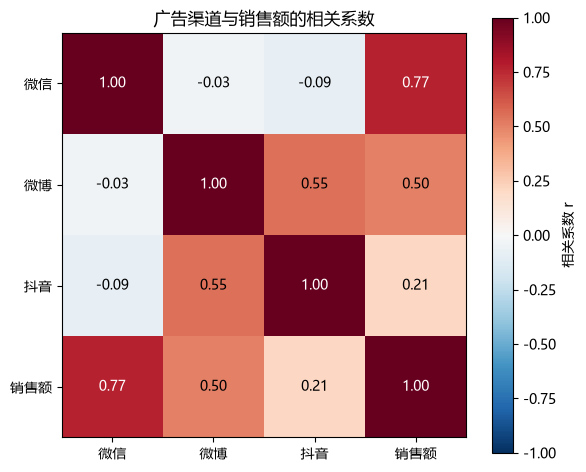

In [37]:
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)

ax.set_xticks(range(len(corr.columns)), corr.columns)
ax.set_yticks(range(len(corr.index)), corr.index)
ax.set_title("广告渠道与销售额的相关系数")

for i in range(len(corr)):
    for j in range(len(corr)):
        value = corr.iloc[i, j]
        color = "white" if abs(value) > 0.55 else "black"
        ax.text(j, i, f"{value:.2f}", ha="center", va="center", color=color)

fig.colorbar(im, ax=ax, label="相关系数 r")
plt.tight_layout()
plt.show()

### 相关系数怎么读

- 微信与销售额：`r ≈ 0.768`，最强正相关；
- 微博与销售额：`r ≈ 0.503`，中等正相关；
- 抖音与销售额：`r ≈ 0.211`，弱正相关；
- 微博与抖音之间：`r ≈ 0.550`，说明老板往往同时加大这两个渠道的投入。

最后一点很重要：微博和抖音之间存在**多重共线性**。在多元回归里，这会让两个渠道的系数变得不稳定，不要单独过度解释某一个系数。

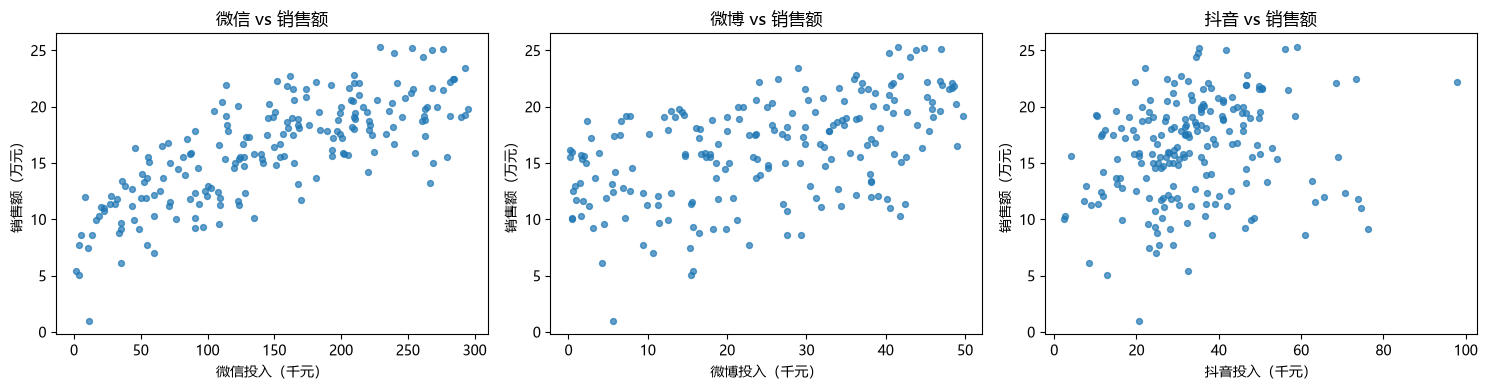

In [38]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, ["微信", "微博", "抖音"]):
    ax.scatter(df[col], df["销售额"], s=18, alpha=0.7)
    ax.set_xlabel(f"{col}投入（千元）")
    ax.set_ylabel("销售额（万元）")
    ax.set_title(f"{col} vs 销售额")

plt.tight_layout()
plt.show()

## 3. 假设函数：一条直线

单特征时，最简单的假设是销售额与微信投入呈直线关系：

$$\hat{y}=wx+b$$

- $x$：这一周的微信投入（千元）；
- $\hat{y}$：模型预测的销售额（万元），帽子表示“估计值”；
- $w$：权重（斜率），表示 $x$ 每增加 1，$\hat{y}$ 增加多少；
- $b$：偏置（截距），表示 $x=0$ 时的基准值。

有 $d$ 个特征时，直线推广成超平面：

$$\hat{y}=w_1x_1+w_2x_2+\cdots+w_dx_d+b=\mathbf{w}^{\top}\mathbf{x}+b$$

### sklearn 要求的数据形状

- `X`：二维数组，形状 `(样本数, 特征数)`，即使只有一个特征也不能是一维；
- `y`：一维数组，形状 `(样本数,)`。

`df['微信']` 是 Series（一维）；`df[['微信']]` 是 DataFrame（二维）。

In [39]:
X = df[["微信"]]
y = df["销售额"]

print("X 形状:", X.shape)
print("y 形状:", y.shape)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("训练集:", X_train.shape, "测试集:", X_test.shape)

X 形状: (200, 1)
y 形状: (200,)
训练集: (160, 1) 测试集: (40, 1)


In [40]:
model = LinearRegression().fit(X_train, y_train)

w = model.coef_[0]
b = model.intercept_

print(f"权重 w = {w:.4f}")
print(f"偏置 b = {b:.4f}")
print(f"假设函数: 销售额 = {w:.4f} × 微信投入 + {b:.4f}")

权重 w = 0.0429
偏置 b = 9.6064
假设函数: 销售额 = 0.0429 × 微信投入 + 9.6064


In [41]:
y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"MAE  : {mae:.3f} 万元")
print(f"RMSE : {rmse:.3f} 万元")
print(f"R²   : {r2:.3f}")
print(f"训练集 R²: {model.score(X_train, y_train):.3f}")

MAE  : 2.362 万元
RMSE : 2.898 万元
R²   : 0.551
训练集 R²: 0.596


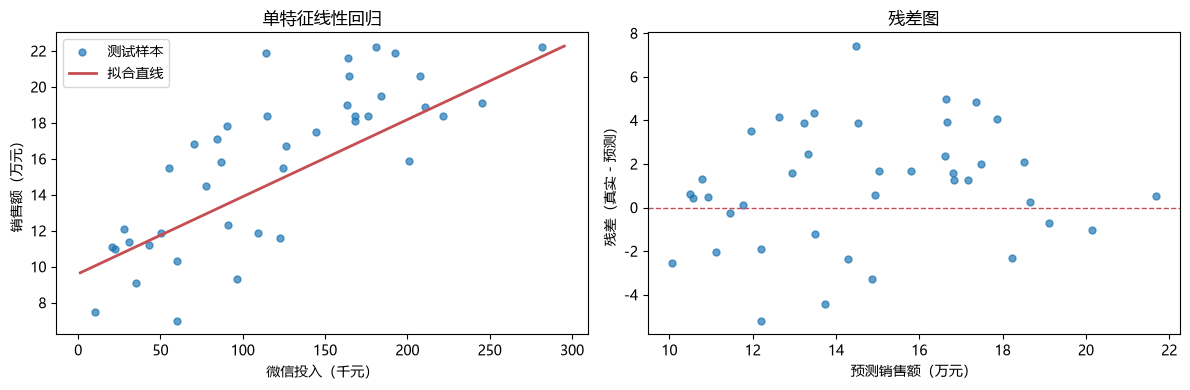

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# 左图：测试样本 + 拟合直线
axes[0].scatter(X_test["微信"], y_test, s=25, alpha=0.7, label="测试样本")
x_line = np.linspace(df["微信"].min(), df["微信"].max(), 100)
y_line = model.predict(pd.DataFrame({"微信": x_line}))
axes[0].plot(x_line, y_line, color="#C44E52", linewidth=2, label="拟合直线")
axes[0].set_xlabel("微信投入（千元）")
axes[0].set_ylabel("销售额（万元）")
axes[0].set_title("单特征线性回归")
axes[0].legend()

# 右图：残差图
residuals = y_test - y_pred
axes[1].scatter(y_pred, residuals, s=25, alpha=0.7)
axes[1].axhline(0, color="#C44E52", linestyle="--", linewidth=1)
axes[1].set_xlabel("预测销售额（万元）")
axes[1].set_ylabel("残差（真实 - 预测）")
axes[1].set_title("残差图")

plt.tight_layout()
plt.show()

### 单特征模型怎么读

- $w$ 的单位是“万元 / 千元”：微信每多投 1 千元，销售额平均增加 $w$ 万元；
- $b$ 是截距，表示微信投入为 0 时的基准销售额；
- $R^2$ 表示模型解释了测试集销售额波动的比例，越接近 1 越好；
- 残差图应围绕 0 随机分布；如果出现明显曲线或喇叭形，说明线性假设可能不够。

## 4. 多特征线性回归

把三个渠道一起放进模型：

$$\hat{y}=w_1x_{\text{微信}}+w_2x_{\text{微博}}+w_3x_{\text{抖音}}+b$$

每个系数表示**控制其他渠道不变**时，该渠道每多投 1 千元，销售额平均变化多少万元。

In [43]:
X_multi = df[["微信", "微博", "抖音"]]
y = df["销售额"]

X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(
    X_multi, y, test_size=0.2, random_state=42
)

model_multi = LinearRegression().fit(X_train_m, y_train_m)

coef_table = pd.DataFrame({
    "特征": X_multi.columns,
    "系数（万元/千元）": model_multi.coef_,
})
coef_table

,特征,系数（万元/千元）
0,微信,0.043242
1,微博,0.167022
2,抖音,-0.006217


In [44]:
for name, coef in zip(X_multi.columns, model_multi.coef_):
    print(f"{name}: 每多投 1 千元，销售额约变化 {coef * 10000:.0f} 元（控制其他渠道不变）")
print(f"截距 b = {model_multi.intercept_:.4f} 万元")

微信: 每多投 1 千元，销售额约变化 432 元（控制其他渠道不变）
微博: 每多投 1 千元，销售额约变化 1670 元（控制其他渠道不变）
抖音: 每多投 1 千元，销售额约变化 -62 元（控制其他渠道不变）
截距 b = 5.7487 万元


In [45]:
y_pred_m = model_multi.predict(X_test_m)

print(f"MAE  : {mean_absolute_error(y_test_m, y_pred_m):.3f} 万元")
print(f"RMSE : {np.sqrt(mean_squared_error(y_test_m, y_pred_m)):.3f} 万元")
print(f"测试集 R²: {r2_score(y_test_m, y_pred_m):.3f}")
print(f"训练集 R²: {model_multi.score(X_train_m, y_train_m):.3f}")

MAE  : 1.403 万元
RMSE : 1.643 万元
测试集 R²: 0.856
训练集 R²: 0.873


In [46]:
comparison = pd.DataFrame({
    "模型": ["微信单特征", "三渠道多特征"],
    "测试集 MAE": [
        mean_absolute_error(y_test, y_pred),
        mean_absolute_error(y_test_m, y_pred_m),
    ],
    "测试集 RMSE": [
        np.sqrt(mean_squared_error(y_test, y_pred)),
        np.sqrt(mean_squared_error(y_test_m, y_pred_m)),
    ],
    "测试集 R²": [
        r2_score(y_test, y_pred),
        r2_score(y_test_m, y_pred_m),
    ],
})
comparison.round(3)

,模型,测试集 MAE,测试集 RMSE,测试集 R²
0,微信单特征,2.362,2.898,0.551
1,三渠道多特征,1.403,1.643,0.856


In [47]:
# 下周计划：微信 200 千元、微博 30 千元、抖音 40 千元
new_week = pd.DataFrame({"微信": [200], "微博": [30], "抖音": [40]})
predicted_sales = model_multi.predict(new_week)[0]
print(f"预测销售额: {predicted_sales:.2f} 万元")

预测销售额: 19.16 万元


## 5. 损失函数与最小二乘法

### 5.1 残差与均方误差

对第 $i$ 个样本，真实值与预测值之差叫**残差**：

$$e_i=y_i-\hat{y}_i$$

残差有正有负，直接相加会互相抵消。最常用的办法是先平方再平均，得到**均方误差**（Mean Squared Error，MSE）：

$$\text{MSE}=\frac{1}{n}\sum_{i=1}^{n}(y_i-\hat{y}_i)^2$$

训练数据 $x_i,y_i$ 是固定的，能变的只有 $w$ 和 $b$，所以损失是参数的函数：

$$L(w,b)=\frac{1}{n}\sum_{i=1}^{n}(y_i-wx_i-b)^2$$

训练就是找一组 $(w,b)$，让 $L(w,b)$ 最小。

### 5.2 为什么是平方，不是绝对值？

另一个自然选择是**平均绝对误差**（Mean Absolute Error，MAE）：

$$\text{MAE}=\frac{1}{n}\sum_{i=1}^{n}|y_i-\hat{y}_i|$$

| 指标 | 优点 | 缺点 |
|---|---|---|
| MSE | 处处光滑可导，对线性模型是凸“碗”，满列秩时最低点唯一 | 误差平方会放大离群点，对异常值敏感 |
| MAE | 对离群点更稳健 | 在误差为 0 处不可导，最优解可能不唯一 |
| Huber | 兼顾两者 | 多一个超参数需要设置 |

线性回归默认用 MSE；异常值很多时可以考虑 MAE 或 Huber。

### 5.3 最小二乘闭式解

对 $b$ 求偏导并令其为 0：

$$\frac{\partial L}{\partial b}=0
\quad\Rightarrow\quad
b=\bar{y}-w\bar{x}$$

这说明最优直线一定穿过平均点 $(\bar{x},\bar{y})$。再对 $w$ 求偏导并令其为 0：

$$w=\frac{\sum_{i=1}^{n}(x_i-\bar{x})(y_i-\bar{y})}
{\sum_{i=1}^{n}(x_i-\bar{x})^2}$$

这就是**最小二乘法**的闭式解。

In [48]:
# 用训练集比较两条候选直线的 MSE
X_train_np = np.asarray(X_train, dtype=float)
y_train_np = np.asarray(y_train, dtype=float)

def predict_line(X, w, b):
    return w * X[:, 0] + b

def mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

print("两条候选直线的训练集 MSE：")
for w, b in [(0.1, 0), (0.04, 10)]:
    y_hat = predict_line(X_train_np, w, b)
    print(f"w={w:<5} b={b:<3} MSE={mse(y_train_np, y_hat):.3f}")

两条候选直线的训练集 MSE：
w=0.1   b=0   MSE=30.627
w=0.04  b=10  MSE=8.360


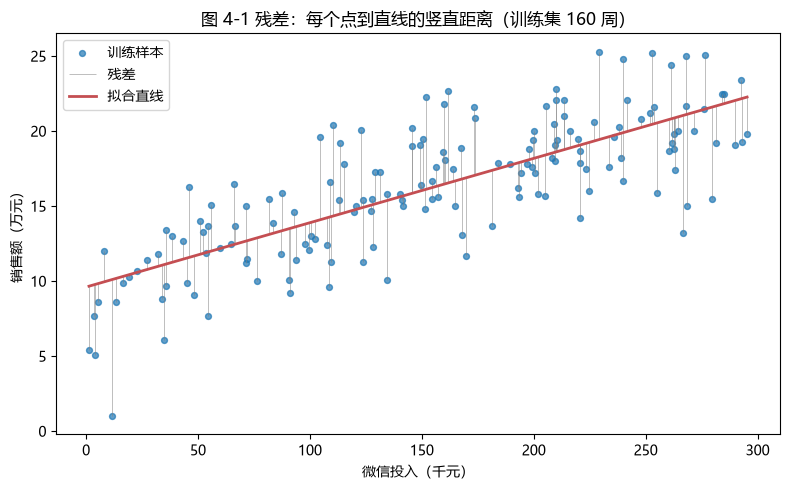

In [49]:
# 图 4-1：残差 = 每个训练样本到拟合直线的竖直距离
y_train_pred = model.predict(X_train)

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(X_train_np[:, 0], y_train_np, s=18, alpha=0.7, label="训练样本")
ax.vlines(
    X_train_np[:, 0],
    np.minimum(y_train_np, y_train_pred),
    np.maximum(y_train_np, y_train_pred),
    color="gray",
    linewidth=0.6,
    alpha=0.6,
    label="残差",
)
x_line = np.linspace(X_train_np[:, 0].min(), X_train_np[:, 0].max(), 100)
y_line = model.predict(pd.DataFrame({"微信": x_line}))
ax.plot(x_line, y_line, color="#C44E52", linewidth=2, label="拟合直线")
ax.set_xlabel("微信投入（千元）")
ax.set_ylabel("销售额（万元）")
ax.set_title("图 4-1 残差：每个点到直线的竖直距离（训练集 160 周）")
ax.legend()
plt.tight_layout()
plt.show()

**讲义原图 4-1：残差**

残差就是每个训练样本到拟合直线的竖直距离。

![图 4-1 残差：每个点到直线的竖直距离（训练集 160 周）](images/notes5_fig4_1_residuals.png)

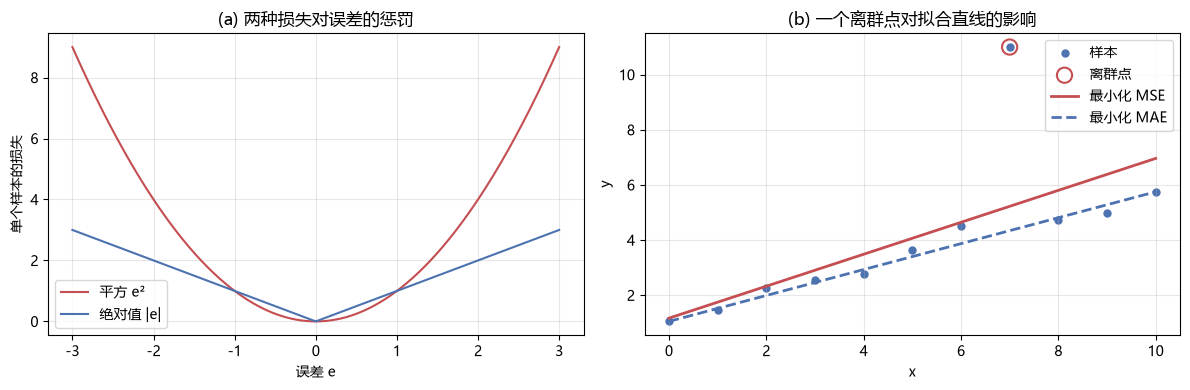

In [50]:
# 图 4-2：MSE 与 MAE 的对比（右图用模拟数据展示离群点的影响）
from sklearn.linear_model import QuantileRegressor

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# (a) 两种损失对误差的惩罚
errors = np.linspace(-3, 3, 400)
axes[0].plot(errors, errors ** 2, color="#C44E52", label="平方 e²")
axes[0].plot(errors, np.abs(errors), color="#4C72B0", label="绝对值 |e|")
axes[0].set_xlabel("误差 e")
axes[0].set_ylabel("单个样本的损失")
axes[0].set_title("(a) 两种损失对误差的惩罚")
axes[0].legend()
axes[0].grid(alpha=0.3)

# (b) 一个离群点对拟合直线的影响
rng = np.random.default_rng(0)
x_demo = np.arange(11, dtype=float)
y_demo = 0.5 * x_demo + 1 + rng.normal(0, 0.4, size=x_demo.size)
y_demo[7] = 11.0  # 人为加入一个离群点
X_demo = x_demo.reshape(-1, 1)

mse_model = LinearRegression().fit(X_demo, y_demo)
mae_model = QuantileRegressor(quantile=0.5, alpha=0, solver="highs").fit(X_demo, y_demo)

axes[1].scatter(x_demo, y_demo, s=25, color="#4C72B0", label="样本")
axes[1].scatter([7], [11], s=120, facecolors="none", edgecolors="#C44E52", linewidth=1.5, label="离群点")
xx = np.linspace(0, 10, 100).reshape(-1, 1)
axes[1].plot(xx, mse_model.predict(xx), color="#C44E52", linewidth=2, label="最小化 MSE")
axes[1].plot(xx, mae_model.predict(xx), color="#4C72B0", linestyle="--", linewidth=2, label="最小化 MAE")
axes[1].set_xlabel("x")
axes[1].set_ylabel("y")
axes[1].set_title("(b) 一个离群点对拟合直线的影响")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

**讲义原图 4-2：MSE 与 MAE**

- (a) 平方误差对大误差的惩罚更重；
- (b) 一个离群点对两条最优直线的影响：MSE 更容易被离群点拉偏。

![图 4-2 MSE 与 MAE](images/notes5_fig4_2_mse_vs_mae.png)

In [51]:
# 一元最小二乘闭式解，并与 sklearn 对照
x = X_train_np[:, 0]
x_bar = x.mean()
y_bar = y_train_np.mean()

w_ls = np.sum((x - x_bar) * (y_train_np - y_bar)) / np.sum((x - x_bar) ** 2)
b_ls = y_bar - w_ls * x_bar

print(f"闭式解: w={w_ls:.4f}, b={b_ls:.4f}")
print(f"闭式解训练集 MSE: {mse(y_train_np, predict_line(X_train_np, w_ls, b_ls)):.3f}")
print(f"sklearn: w={model.coef_[0]:.4f}, b={model.intercept_:.4f}")
print("两者是否一致:", np.allclose([w_ls, b_ls], [model.coef_[0], model.intercept_]))

闭式解: w=0.0429, b=9.6064
闭式解训练集 MSE: 8.302
sklearn: w=0.0429, b=9.6064
两者是否一致: True


## 6. 多特征：正规方程

多个特征时，把样本排成设计矩阵 $X$，并在最后补一列 1：

$$X=
\begin{bmatrix}
x_{11} & \cdots & x_{1d} & 1\\
\vdots & & \vdots & \vdots\\
x_{n1} & \cdots & x_{nd} & 1
\end{bmatrix},
\qquad
\theta=
\begin{bmatrix}
w_1\\ \vdots\\ w_d\\ b
\end{bmatrix}
$$

预测值和损失写成：

$$\hat{\mathbf{y}}=X\theta,
\qquad
L(\theta)=\frac{1}{n}\|\mathbf{y}-X\theta\|^2$$

对 $\theta$ 求梯度并令其为零，得到**正规方程**：

$$X^{\top}X\theta=X^{\top}\mathbf{y}$$

当 $X^{\top}X$ 可逆时：

$$\theta=(X^{\top}X)^{-1}X^{\top}\mathbf{y}$$

### 为什么要补最后一列 1？

- 不补 1：模型是 $\hat{y}=w_1x_1+\cdots+w_dx_d$，强制过原点；
- 补 1：第 $d+1$ 个权重就是偏置 $b$，$X\theta$ 自动算出 $\sum w_jx_j+b$。

sklearn 的 `LinearRegression(fit_intercept=True)` 会在内部自动完成这件事。

In [52]:
# 多特征正规方程：给设计矩阵补一列 1
X_train_m_np = np.asarray(X_train_m, dtype=float)
X_test_m_np = np.asarray(X_test_m, dtype=float)
y_train_m_np = np.asarray(y_train_m, dtype=float)

X_design_train = np.c_[X_train_m_np, np.ones(len(X_train_m_np))]
X_design_test = np.c_[X_test_m_np, np.ones(len(X_test_m_np))]

XtX = X_design_train.T @ X_design_train
theta_inv = np.linalg.inv(XtX) @ X_design_train.T @ y_train_m_np
theta_lstsq = np.linalg.lstsq(X_design_train, y_train_m_np, rcond=None)[0]

print("正规方程 inv  :", np.round(theta_inv, 4))
print("正规方程 lstsq:", np.round(theta_lstsq, 4))
print("sklearn       :", np.round(np.r_[model_multi.coef_, model_multi.intercept_], 4))
print("条件数 cond(XᵀX):", round(np.linalg.cond(XtX), 1))

正规方程 inv  : [ 0.0432  0.167  -0.0062  5.7487]
正规方程 lstsq: [ 0.0432  0.167  -0.0062  5.7487]
sklearn       : [ 0.0432  0.167  -0.0062  5.7487]
条件数 cond(XᵀX): 335071.0


In [53]:
# 用 np.linalg.solve 解正规方程：直接解线性方程组，不显式求逆
theta_solve = np.linalg.solve(XtX, X_design_train.T @ y_train_m_np)
print("正规方程 solve:", np.round(theta_solve, 4))
print("与 inv 的最大差异  :", np.max(np.abs(theta_solve - theta_inv)))
print("与 lstsq 的最大差异:", np.max(np.abs(theta_solve - theta_lstsq)))
print(
    "与 sklearn 的最大差异:",
    np.max(np.abs(theta_solve - np.r_[model_multi.coef_, model_multi.intercept_])),
)

正规方程 solve: [ 0.0432  0.167  -0.0062  5.7487]
与 inv 的最大差异  : 3.552713678800501e-15
与 lstsq 的最大差异: 2.398081733190338e-14
与 sklearn 的最大差异: 1.865174681370263e-14


In [54]:
# 正规方程与 sklearn 的预测对照
pred_theta = X_design_test @ theta_inv
pred_sklearn = model_multi.predict(X_test_m)
print("正规方程与 sklearn 预测的最大差异:", np.max(np.abs(pred_theta - pred_sklearn)))

# 不补 1 列：模型强制过原点
theta_no_bias = np.linalg.lstsq(X_train_m_np, y_train_m_np, rcond=None)[0]
print("不补 1 的系数:", np.round(theta_no_bias, 4))
print("训练集 MSE（补 1）:", round(mse(y_train_m_np, X_design_train @ theta_inv), 3))
print("训练集 MSE（不补 1）:", round(mse(y_train_m_np, X_train_m_np @ theta_no_bias), 3))

正规方程与 sklearn 预测的最大差异: 3.197442310920451e-14
不补 1 的系数: [0.0568 0.1884 0.0735]
训练集 MSE（补 1）: 2.606
训练集 MSE（不补 1）: 5.746


### 正规方程的局限

1. $X^{\top}X$ 必须可逆；特征严重共线时可能奇异或病态。本例 $X^{\top}X$ 的条件数约为 $3.35\times10^5$，说明特征尺度差异和微博/抖音相关性让矩阵偏病态，系数解释要谨慎。
2. 计算 $X^{\top}X$ 的复杂度约为 $O(nd^2)$，求逆约为 $O(d^3)$；样本量或特征数很大时计算慢、占内存，此时改用梯度下降。
3. 适合样本不多、特征数量不大的场景，可以一步求解，不用迭代。
4. 共线性严重时，可以用 Ridge 正则化或删除冗余特征。

## 7. 梯度下降

第 5、6 节的两种解法——一元的闭式解和多元的正规方程——都是**一步算出答案**。但它们各有短板：

1. 正规方程要求 $X^{\top}X$ 可逆，造 $X^{\top}X$ 约 $O(nd^2)$、求逆约 $O(d^3)$，特征成千上万时非常慢；
2. 逻辑回归、神经网络等模型根本写不出闭式解。

**梯度下降**是另一条路：不一步算到底，而是一小步一小步往山下走。

> 想象你站在山腰，大雾里看不见谷底，只能感觉到脚下的坡往哪边斜。策略是：沿着**坡度最陡方向的反方向**迈一小步；每走一步重新感受坡度，再决定下一步；直到脚下几乎平地（梯度 ≈ 0），就停下来。

- 山 = 损失函数 $L(w,b)$，横坐标是参数 $w,b$，纵坐标是损失值，越低越好；
- 坡度 = 梯度（偏导数），指向**上坡最陡**的方向，所以要反着走；
- 走法：每轮同时更新两个参数

$$w \leftarrow w-\eta\frac{\partial L}{\partial w},\qquad
b \leftarrow b-\eta\frac{\partial L}{\partial b}$$

其中 $\eta$（读作 eta）是**学习率**，决定每一步迈多大。

梯度下降和最小二乘、正规方程的**目标完全一样**：都是找让 MSE 最小的 $(w,b)$。区别只在找法——正规方程是"解方程直接得到谷底坐标"，梯度下降是"一步一步走下去"。

### 7.1 MSE 的梯度

线性回归的损失是均方误差：

$$L(w,b)=\frac{1}{n}\sum_{i=1}^{n}\bigl(y_i-(wx_i+b)\bigr)^2$$

对两个参数分别求偏导（对平方项用链式法则）：

$$\frac{\partial L}{\partial w}=\frac{2}{n}\sum_{i=1}^{n}(\hat{y}_i-y_i)\,x_i,
\qquad
\frac{\partial L}{\partial b}=\frac{2}{n}\sum_{i=1}^{n}(\hat{y}_i-y_i)$$

两个式子的含义很直观：

- $\hat{y}_i-y_i$ 是第 $i$ 个样本"猜多了多少"。如果整体猜多了，梯度为正，参数就往下调；
- 对 $w$ 的梯度还要乘 $x_i$，因为 $x_i$ 越大的样本，$w$ 的变化对它的预测影响越大。

所以每一轮要做的事只有三件：算预测 $\hat{y}$、算两个梯度、沿反方向更新参数。

### 7.2 一元案例：先按原始尺度走 5000 步

用一组模拟数据练手：面积（平方米）→ 房价（万元），真实规律是 $\hat{y}=x+30$。按讲义的参数直接跑：学习率 $10^{-5}$，迭代 5000 次。

In [55]:
# 模拟数据：面积（平方米）→ 房价（万元）
area = np.array([60, 80, 100, 120, 140], dtype=float)
price = np.array([90, 110, 130, 150, 170], dtype=float)
n = len(area)

# 从 (0, 0) 出发，和讲义参数保持一致
w, b = 0.0, 0.0
lr = 1e-5
epochs = 5000

loss_raw = []
for i in range(epochs):
    y_hat = w * area + b
    dw = (2 / n) * np.sum((y_hat - price) * area)
    db = (2 / n) * np.sum(y_hat - price)
    w -= lr * dw
    b -= lr * db
    loss_raw.append(np.mean((y_hat - price) ** 2))

    if i % 1000 == 0:
        print(f"第{i:5d}轮 | w={w:7.4f} b={b:8.3f} | dw={dw:10.2f} db={db:9.2f} | MSE={loss_raw[-1]:8.2f}")

print(f"\n训练结束：w={w:.4f}, b={b:.3f}, 训练集 MSE={loss_raw[-1]:.3f}")
print("最小二乘闭式解：w=1, b=30, 训练集 MSE=0")

第    0轮 | w= 0.2760 b=   0.003 | dw= -27600.00 db=  -260.00 | MSE=17700.00
第 1000轮 | w= 1.2773 b=   0.056 | dw=      0.04 db=    -4.44 | MSE=   66.42
第 2000轮 | w= 1.2768 b=   0.101 | dw=      0.04 db=    -4.43 | MSE=   66.22
第 3000轮 | w= 1.2764 b=   0.145 | dw=      0.04 db=    -4.42 | MSE=   66.02
第 4000轮 | w= 1.2760 b=   0.189 | dw=      0.04 db=    -4.42 | MSE=   65.83

训练结束：w=1.2756, b=0.233, 训练集 MSE=65.635
最小二乘闭式解：w=1, b=30, 训练集 MSE=0


**结果说明：5000 步还没走到谷底。**

$w$ 停在 1.28 附近，而 $b$ 才 0.23（真值 30），MSE 还有 65 左右。这不是代码写错，而是**尺度问题**：

- $x$ 在 60~140 之间，$w$ 的梯度里带着 $x$，量级是几千；$b$ 的梯度只有几百；
- 学习率却只有一个。$10^{-5}$ 对 $w$ 方向算合适，对 $b$ 方向就太小了——每步只挪 $10^{-5}\times260\approx0.0026$，要走到 30 需要上万步；
- 换个角度看，此时的损失面是一个"又长又窄的峡谷"（条件数很大），沿着长轴方向下降极慢。

正确做法不是硬调一个更大的学习率（$w$ 方向会直接炸掉），而是**先把特征标准化**，让两个方向的尺度站在同一起跑线上。

标准化空间：W=28.2843, B=130.000
换回原尺度：w=1.0000, b=30.0000, 训练集 MSE=1.23e-26


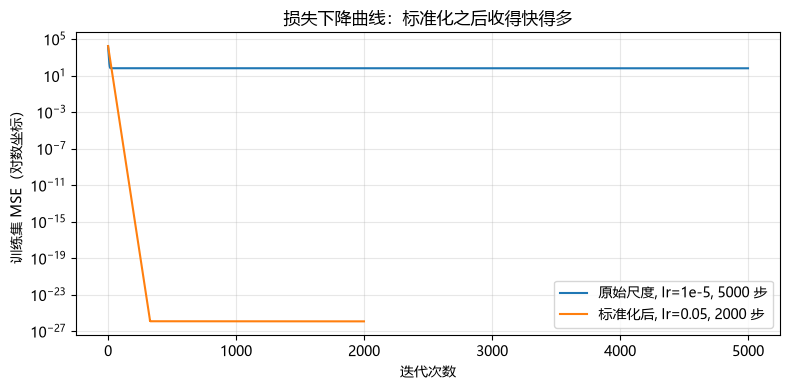

In [56]:
# 只对特征做 Z-score 标准化：z = (x - μ) / σ
mu, sigma = area.mean(), area.std()
z = (area - mu) / sigma

W, B = 0.0, 0.0
lr = 0.05
epochs = 2000

loss_std = []
for i in range(epochs):
    y_hat = W * z + B
    dW = (2 / n) * np.sum((y_hat - price) * z)
    dB = (2 / n) * np.sum(y_hat - price)
    W -= lr * dW
    B -= lr * dB
    loss_std.append(np.mean((y_hat - price) ** 2))

# W、B 是"标准化空间"里的参数，换回原尺度才能读成"每平方米多少钱"
w_fit = W / sigma
b_fit = B - W * mu / sigma

print(f"标准化空间：W={W:.4f}, B={B:.3f}")
print(f"换回原尺度：w={w_fit:.4f}, b={b_fit:.4f}, 训练集 MSE={loss_std[-1]:.2e}")

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(loss_raw, label="原始尺度, lr=1e-5, 5000 步")
ax.plot(loss_std, label="标准化后, lr=0.05, 2000 步")
ax.set_yscale("log")
ax.set_xlabel("迭代次数")
ax.set_ylabel("训练集 MSE（对数坐标）")
ax.set_title("损失下降曲线：标准化之后收得快得多")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 7.3 学习率：步子迈多大才合适

$\eta$ 是梯度下降最重要的超参数：

- **$\eta$ 太小**：每步挪一点点，下山极慢，循环几万次还没到谷底；
- **$\eta$ 太大**：一步跨过谷底，在两边来回震荡，甚至越走越高、损失变成 `inf`（发散）；
- **合适**：损失曲线平稳单调地下降。

判断办法很朴素：**看损失曲线**。稳定下降就是对的；来回弹或突然变成 `inf`/`nan`，就是学习率太大了。

注意：学习率的合理范围和特征尺度强相关。原始尺度下 $10^{-5}$ 都算偏大，标准化之后 $0.05$ 反而很稳——这也是 7.2 节要先做标准化的原因之一。

In [57]:
# 同一份标准化数据，只改学习率
for lr_test in [0.001, 0.05, 1.1]:
    W_test, B_test = 0.0, 0.0
    last_loss = np.nan
    diverged_at = None

    with np.errstate(over="ignore", invalid="ignore"):
        for i in range(2000):
            y_hat = W_test * z + B_test
            dW = (2 / n) * np.sum((y_hat - price) * z)
            dB = (2 / n) * np.sum(y_hat - price)
            W_test -= lr_test * dW
            B_test -= lr_test * dB
            last_loss = np.mean((y_hat - price) ** 2)
            if not np.isfinite(last_loss):
                diverged_at = i
                break

    if diverged_at is not None:
        print(f"lr={lr_test:<6} 第 {diverged_at} 轮发散，损失变成 inf")
    else:
        print(f"lr={lr_test:<6} 2000 轮后 MSE={last_loss:.3e}")

lr=0.001  2000 轮后 MSE=5.914e+00
lr=0.05   2000 轮后 MSE=1.232e-26
lr=1.1    第 1916 轮发散，损失变成 inf


### 7.4 多特征：在广告数据上跑一遍

多个特征时，梯度写成矩阵形式，代码几乎不用改——只是把标量换成向量：

$$\hat{\mathbf{y}}=X\mathbf{w}+b,
\qquad
\frac{\partial L}{\partial \mathbf{w}}=\frac{2}{n}X^{\top}(\hat{\mathbf{y}}-\mathbf{y})$$

用三渠道数据（微信、微博、抖音 → 销售额）跑一遍，应该能复现第 4 节 sklearn 学到的那组系数。注意这里**先对特征做标准化**，否则各渠道投入范围不同（微信 1~295、微博 0.2~50），梯度下降会走得很艰难。

In [58]:
# 三渠道数据（沿用第 4 节的训练集划分）
X_gd = np.asarray(X_train_m, dtype=float)
y_gd = np.asarray(y_train_m, dtype=float)
n_gd = len(X_gd)

# 用训练集的均值和标准差做标准化
mu_gd, sd_gd = X_gd.mean(axis=0), X_gd.std(axis=0)
Z_gd = (X_gd - mu_gd) / sd_gd

theta = np.zeros(X_gd.shape[1])
b_gd = 0.0
lr = 0.1
epochs = 3000

loss_gd = []
for i in range(epochs):
    y_hat = Z_gd @ theta + b_gd
    grad_w = (2 / n_gd) * Z_gd.T @ (y_hat - y_gd)
    grad_b = (2 / n_gd) * np.sum(y_hat - y_gd)
    theta -= lr * grad_w
    b_gd -= lr * grad_b
    loss_gd.append(np.mean((y_hat - y_gd) ** 2))

# 换回原始尺度：w_j = θ_j / σ_j，截距再按各特征的均值补偿
w_gd = theta / sd_gd
b_gd_orig = b_gd - np.sum(w_gd * mu_gd)

print("梯度下降：", np.round(w_gd, 4), f"b = {b_gd_orig:.4f}")
print("sklearn ：", np.round(model_multi.coef_, 4), f"b = {model_multi.intercept_:.4f}")
print(f"训练集 MSE（梯度下降）: {loss_gd[-1]:.4f}")
print(f"训练集 MSE（sklearn） : {mean_squared_error(y_train_m, model_multi.predict(X_train_m)):.4f}")

梯度下降： [ 0.0432  0.167  -0.0062] b = 5.7487
sklearn ： [ 0.0432  0.167  -0.0062] b = 5.7487
训练集 MSE（梯度下降）: 2.6059
训练集 MSE（sklearn） : 2.6059


### 7.5 梯度下降 vs 正规方程

| | 正规方程 | 梯度下降 |
|---|---|---|
| 做法 | 解方程，一步到位 | 迭代，一小步一小步 |
| 超参数 | 不需要 | 学习率、迭代次数 |
| 每轮计算量 | 造 $X^{\top}X$ 约 $O(nd^2)$，求逆约 $O(d^3)$ | 每轮约 $O(nd)$ |
| 求解条件 | $X^{\top}X$ 必须可逆 | 无矩阵求逆，几乎不挑数据 |
| 适用场景 | 样本少、特征少 | 大数据、高维特征、神经网络 |
| 结果 | 闭式解，精确 | 逼近解，受学习率和迭代次数影响 |

> 两者目标相同，都是最小化 MSE。小数据用正规方程一步搞定；数据大、模型复杂时，梯度下降是唯一可行的通用办法。

## 8. 回归模型怎么评估：MAE、RMSE、R²

前面第 3、4 节已经在用这三个指标了，这里集中说清楚它们的定义和读法。

### 8.1 三个指标

**MAE（平均绝对误差）**：预测值和真实值平均差多少，单位与 $y$ 相同。

$$\text{MAE}=\frac{1}{n}\sum_{i=1}^{n}|y_i-\hat{y}_i|$$

**RMSE（均方根误差）**：先平方、求平均、再开根号，单位也与 $y$ 相同。

$$\text{RMSE}=\sqrt{\frac{1}{n}\sum_{i=1}^{n}(y_i-\hat{y}_i)^2}$$

**R²（决定系数）**：和"无脑猜平均值"这个基准比，模型强多少。

$$R^2=1-\frac{\sum_{i=1}^{n}(y_i-\hat{y}_i)^2}{\sum_{i=1}^{n}(y_i-\bar{y})^2}$$

其中 $\bar{y}$ 是**测试集真实值的均值**。分母就是"不管输入是什么，永远预测均值"时的误差平方和。

### 8.2 怎么选

| 指标 | 范围 | 越小越好？ | 核心作用 |
|---|---|---|---|
| MAE | $\ge 0$ | 是 | 直观：平均误差多少，业务汇报首选 |
| RMSE | $\ge 0$ | 是 | 严惩大偏差（平方放大），工业建模常用 |
| R² | $\le 1$ | 越接近 1 越好 | 对比基准，判断模型到底有没有用，可跨数据集比较 |

恒有 $\text{RMSE}\ge\text{MAE}$；两者差距越大，说明误差里存在个别特别大的偏差。

In [59]:
def report(name, y_true, y_pred):
    """一次性打印三个指标，方便横向对比"""
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    print(f"{name:<14} MAE={mae:5.3f}  RMSE={rmse:5.3f}  R²={r2:6.3f}")

report("微信单特征", y_test, y_pred)
report("三渠道多特征", y_test_m, y_pred_m)

# 基准模型：不管输入是什么，永远预测训练集的均值
baseline_pred = np.full(len(y_test_m), y_train_m.mean())
report("基准（猜均值）", y_test_m, baseline_pred)

微信单特征          MAE=2.362  RMSE=2.898  R²= 0.551
三渠道多特征         MAE=1.403  RMSE=1.643  R²= 0.856
基准（猜均值）        MAE=3.693  RMSE=4.352  R²=-0.013


### 8.3 怎么读这些数

- 基准模型的 $R^2$ 约等于 0（这里是 −0.013，略有波动），MAE 明显大于真正的模型。这说明两个模型都比"瞎猜均值"强，特征确实有用；
- $R^2=1$：完美预测；$R^2=0$：和猜均值一样，模型等于没用；$R^2<0$：比猜均值还差，说明特征没用或模型搭错了；
- 测试集上 $R^2$ 可以是负数——因为基准用的是**训练集**均值，不是测试集均值；
- 本例 $R^2\approx0.856$，可以理解为：三个渠道的投入解释了测试集销售额波动的 85.6%；
- MAE 和 RMSE 的单位都是"万元"，可以直接对业务解释：三渠道模型的预测平均差 1.4 万元左右；RMSE 更大，因为平方放大了几个偏差较大的样本。

> 注意：$R^2$ 只在**同一份数据、同一个任务**之间比较才有意义；不同数据集之间比较，优先看 $R^2$ 的相对高低，不要直接拿 MAE 跨数据集比。

## 9. 标准化后的系数：谁的影响更大？

第 4 节出现过一件容易误解的事：微博的系数（0.167）比微信（0.043）大得多，但微信和销售额的相关系数（0.768）却比微博（0.503）高。

**不能直接比原始系数的大小。** 系数的单位是"万元 / 千元"，但两个渠道的投入范围差得很远：

- 微信：约 1~295 千元，标准差约 80；
- 微博：约 0.2~50 千元，标准差约 14。

"多投 1 千元"对这两个渠道的意义完全不同。微信加 1 千元只是常规操作，微博加 1 千元可能是翻倍——同样的 +1，变量本身的波动幅度不一样，系数自然不能放在一起比。

**做法：先标准化，再比较。** 用 `StandardScaler` 把每个特征变成均值 0、标准差 1，再回归。此时系数变成"这个特征变化 1 个标准差，销售额变化多少万元"，单位和波动幅度都被抹平了。

In [60]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# 流水线：先标准化，再线性回归（拟合、预测都绑在一起）
std_lr = make_pipeline(StandardScaler(), LinearRegression()).fit(X_train_m, y_train_m)

coef_compare = pd.DataFrame({
    "特征": X_train_m.columns,
    "原始系数（万元/千元）": model_multi.coef_,
    "标准化系数（万元/标准差）": std_lr[-1].coef_,
})
coef_compare.round(3)

,特征,原始系数（万元/千元）,标准化系数（万元/标准差）
0,微信,0.043,3.528
1,微博,0.167,2.433
2,抖音,-0.006,-0.089


In [61]:
# 标准化只改变系数的读法，不改变预测值
print("标准化前后的预测是否一致:", np.allclose(std_lr.predict(X_test_m), y_pred_m))
print("标准化前后的 R²:", round(r2_score(y_test_m, std_lr.predict(X_test_m)), 3),
      round(r2_score(y_test_m, y_pred_m), 3))

标准化前后的预测是否一致: True
标准化前后的 R²: 0.856 0.856


### 9.1 结论

标准化之后可以直接排序了：

- 微信 +3.53：投入每增加 1 个标准差，销售额平均增加约 3.53 万元，**影响最大**；
- 微博 +2.43：次之；
- 抖音 −0.09：几乎为 0，在微信、微博已经入模的前提下没有额外信息。

这个排序和相关系数给出的结论（微信 > 微博 > 抖音）一致，所以第 4 节那个"微博系数更大"的困惑就解开了：**原始系数的大小混进了特征自身的波动幅度，标准化系数才是公平的比较。**

两个必须记住的点：

1. **标准化不改变模型能力**：预测值、R² 完全一样，只是系数的单位和读法变了；
2. **标准化之后不能再用原公式手算预测**：新样本必须先用同一组均值、标准差标准化，再代入。这也是 `Pipeline` 的价值——它把"先标准化、再预测"绑在一起，避免忘记或者用错参数。

## 11. 过拟合与正则化

### 11.0 过拟合是怎么来的

普通线性回归只最小化 MSE，不限制权重的大小。特征很多、样本不多时，模型会把训练数据里的噪声也学进去：训练 MSE 很低，新数据误差很大。

根源：为了继续降低训练误差，优化器会把某些权重调得特别大；权重一大，输入稍微波动，输出就剧烈变化。

### 11.1 正则化

在损失函数里加一个惩罚项：

$$L = \underbrace{\frac{1}{n}\sum_{i=1}^{n}(y_i-\hat{y}_i)^2}_{\text{拟合训练数据}}
\;+\;
\underbrace{\lambda\cdot\text{penalty}(w)}_{\text{约束权重}}$$

| 类型 | 惩罚项 | 模型 | 特点 |
|---|---|---|---|
| L2 | $\lambda\sum_j w_j^2$ | Ridge 岭回归 | 把权重整体压小，但一般不会变成 0，所有特征都保留一点贡献 |
| L1 | $\lambda\sum_j |w_j|$ | Lasso 套索回归 | 可以把不重要特征的权重直接压到 0，自带特征选择 |

`alpha`（讲义里写作 $\lambda$）是正则强度：

- `alpha=0`：普通线性回归；
- `alpha` 太小：惩罚弱，仍然过拟合；
- `alpha` 太大：有用特征的权重也被压没，变成欠拟合。

注意：**做 L1/L2 正则前必须先标准化**，否则惩罚对量纲大的特征不公平；截距通常不参与惩罚。

In [62]:
from sklearn.linear_model import Lasso, Ridge
from sklearn.preprocessing import StandardScaler

# 150 个样本、25 个特征，只有前两个特征真正有用
np.random.seed(42)
n_samples, n_features = 150, 25
X_reg = np.random.randn(n_samples, n_features)
true_w = np.array([3.5, -2.8] + [0] * (n_features - 2))
y_reg = X_reg @ true_w + np.random.normal(0, 1.0, size=n_samples)

X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X_reg, y_reg, test_size=0.3, random_state=42
)

# 正则化前先标准化，保证惩罚对每个特征公平
scaler_r = StandardScaler()
X_train_r = scaler_r.fit_transform(X_train_r)
X_test_r = scaler_r.transform(X_test_r)

models = {
    "普通线性回归": LinearRegression(),
    "Ridge (alpha=1.2)": Ridge(alpha=1.2),
    "Lasso (alpha=0.14)": Lasso(alpha=0.14),
}

rows = []
for name, model in models.items():
    model.fit(X_train_r, y_train_r)
    rows.append({
        "模型": name,
        "训练 MSE": mean_squared_error(y_train_r, model.predict(X_train_r)),
        "测试 MSE": mean_squared_error(y_test_r, model.predict(X_test_r)),
        "非零权重数": int(np.sum(np.abs(model.coef_) > 1e-8)),
    })

reg_results = pd.DataFrame(rows)
reg_results.round(4)

,模型,训练 MSE,测试 MSE,非零权重数
0,普通线性回归,0.6511,1.0857,25
1,Ridge (alpha=1.2),0.6550,1.0202,25
2,Lasso (alpha=0.14),0.7956,0.7840,3


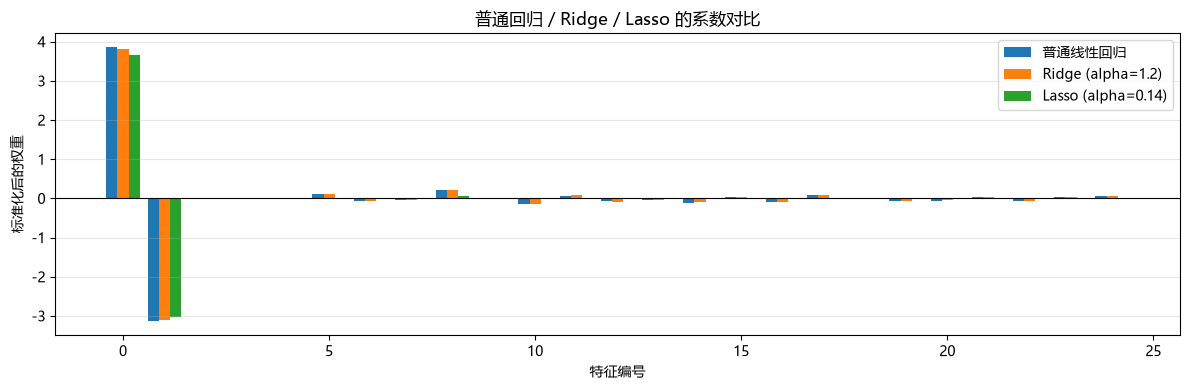

In [63]:
# 三个模型的系数对比：Lasso 把大部分噪声特征压成了 0
fig, ax = plt.subplots(figsize=(12, 4))
indices = np.arange(n_features)
width = 0.27

for offset, (name, model) in zip([-width, 0, width], models.items()):
    ax.bar(indices + offset, model.coef_, width=width, label=name)

ax.axhline(0, color="black", linewidth=0.8)
ax.set_xlabel("特征编号")
ax.set_ylabel("标准化后的权重")
ax.set_title("普通回归 / Ridge / Lasso 的系数对比")
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

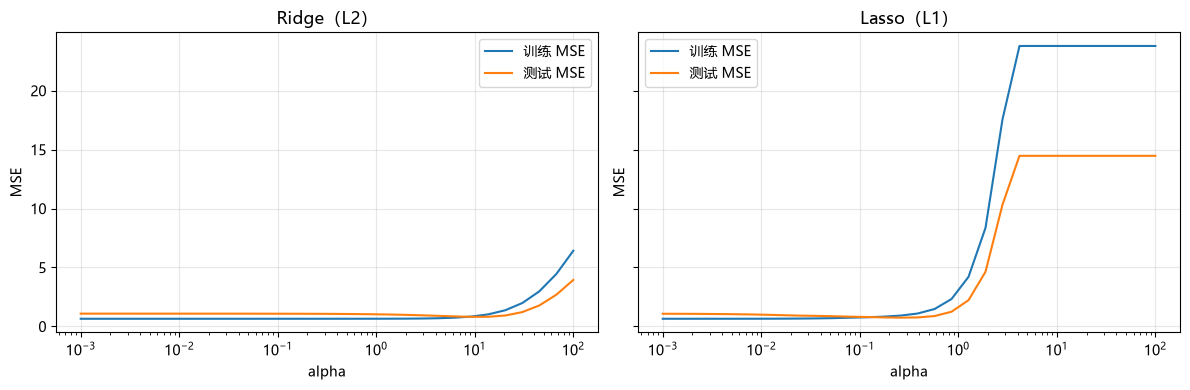

In [64]:
# alpha 从 0.001 到 100 扫描：看正则强度对训练/测试误差的影响
import warnings

from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import Lasso, Ridge

alphas = np.logspace(-3, 2, 30)
ridge_train, ridge_test = [], []
lasso_train, lasso_test = [], []

with warnings.catch_warnings():
    warnings.simplefilter("ignore", ConvergenceWarning)
    for alpha in alphas:
        ridge = Ridge(alpha=alpha).fit(X_train_r, y_train_r)
        ridge_train.append(mean_squared_error(y_train_r, ridge.predict(X_train_r)))
        ridge_test.append(mean_squared_error(y_test_r, ridge.predict(X_test_r)))

        lasso = Lasso(alpha=alpha, max_iter=10000).fit(X_train_r, y_train_r)
        lasso_train.append(mean_squared_error(y_train_r, lasso.predict(X_train_r)))
        lasso_test.append(mean_squared_error(y_test_r, lasso.predict(X_test_r)))

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, train_scores, test_scores, title in [
    (axes[0], ridge_train, ridge_test, "Ridge（L2）"),
    (axes[1], lasso_train, lasso_test, "Lasso（L1）"),
]:
    ax.plot(alphas, train_scores, label="训练 MSE")
    ax.plot(alphas, test_scores, label="测试 MSE")
    ax.set_xscale("log")
    ax.set_xlabel("alpha")
    ax.set_ylabel("MSE")
    ax.set_title(title)
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### 11.1 结果怎么读

- 普通线性回归用满 25 个特征，训练 MSE 最低，但测试 MSE 最高；
- Ridge 把权重整体压小，测试 MSE 下降；
- Lasso 训练 MSE 更高，但测试 MSE 最低，并且只保留 3 个非零权重（真实两个 + 一个很小的噪声特征），体现了稀疏化和特征选择；
- 训练误差低不等于泛化好。正则化是在“拟合训练数据”和“控制模型复杂度”之间做平衡。

### 11.2 alpha 怎么选

alpha 不能拍脑袋定。正确做法是用验证集或交叉验证：对每个 alpha 做 K 折交叉验证，选平均验证误差最小的那一组。测试集只用于最后评估，不能拿来选 alpha。

## 12. 结果解读与注意点

### 结果

- 单特征（微信）测试集 $R^2 \approx 0.551$；
- 三渠道多特征测试集 $R^2 \approx 0.856$，加入微博、抖音后明显提升；
- 多特征模型里，微博的原始系数比微信大，但微信与销售额的**相关系数**更高。这两件事不矛盾：相关系数看的是单独变化，回归系数看的是**控制其他渠道后**的边际贡献；要比较“谁更重要”，先标准化再比（见第 9 节）；
- 抖音系数接近 0（甚至略为负），说明在微信、微博已经进入模型后，抖音的额外信息很少；
- 微博与抖音相关性 0.55，存在多重共线性，系数解释要谨慎；
- 闭式解和正规方程与 sklearn 的 `LinearRegression` 结果一致；给设计矩阵补一列 1 等价于 `fit_intercept=True`；
- 梯度下降在**标准化之后**同样能收敛到同一组系数（见第 7 节）；
- 正则化实验：25 个特征中只有 2 个真正有用。普通回归用满 25 个特征；Ridge 把权重整体压小；Lasso 把大部分噪声特征压到 0，测试 MSE 最低（见第 11 节）。

### 注意

1. **相关不等于因果**：模型能预测，不代表“多投微博就一定多卖”。
2. **线性假设**：残差图若有明显结构，可能需要对数变换、多项式或交互项。
3. **训练集 / 测试集**：测试集只用于最终评估，不能拿来调参。
4. **异常值**：线性回归对异常值敏感，建模前应先检查散点图。
5. **多重共线性**：相关系数高的特征不要同时过度解释；可用 VIF、正则化（Ridge/Lasso）处理。
6. **正规方程**：要求 $X^{\top}X$ 可逆；样本或特征很大时计算慢，应改用梯度下降。
7. **梯度下降的尺度问题**：特征量纲不同时先标准化，否则学习率很难同时照顾到所有参数；学习率太大发散、太小极慢，判断依据是损失曲线。
8. **评估指标要配套**：MAE / RMSE 看误差绝对大小，$R^2$ 看相对基准的提升；不要跨数据集直接比较 MAE。
9. **正则化前先标准化**：否则惩罚会偏向数值大的特征；alpha 要用验证集/交叉验证选，不能拿测试集选。

### 练习

1. 只把微博或只把抖音作为单特征，比较 $R^2$。
2. 对销售额做对数变换，观察 $R^2$ 和残差图是否改善。
3. 加入交互项（如微信 × 微博），看模型是否更好。
4. 用 `cross_val_score` 做 5 折交叉验证，比较单特征与多特征的稳定性。
5. 用 `StandardScaler` 标准化特征后再回归，观察系数变化（预测值不变）。
6. 用正规方程手算多特征系数，并与 sklearn 对照；再去掉 1 列，观察预测和 MSE 的变化。
7. 用梯度下降拟合三渠道数据：分别试 `lr=0.001 / 0.1 / 1.0`，画出损失曲线，找出能稳定收敛的最大学习率。
8. 梯度下降时**不标准化**特征，观察收敛需要多少轮，和标准化后对比。
9. 对 Ridge / Lasso 做 alpha 扫描，用验证集或交叉验证选择最佳 alpha。
10. 比较普通回归、Ridge、Lasso 的训练/测试 MSE 和非零系数数量。
11. 运行 `python src/train.py` 与 `python src/train.py --config configs/linear.yaml`，比较 `reports/metrics.json` 中的配置和结果。